# Optimizer 3: Mini-batch SGD (batch size 32)

The original used `MLPRegressor(solver='sgd')`, which has a hidden layer. Real logistic regression has no hidden layer, so this uses a single `nn.Linear` layer trained with `optim.SGD` on mini-batches of 32.

**Task:** predict whether a person earns more than 50K (`adult-training.csv`). Put the CSV in the same folder as this notebook.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, log_loss, confusion_matrix, classification_report)

In [2]:
cols = ['age','workclass','fnlwgt','education','education_num','marital_status','occupation',
        'relationship','race','sex','capital_gain','capital_loss','hours_per_week','native_country','income']
data = pd.read_csv('adult-training.csv', header=None, names=cols, skipinitialspace=True, na_values='?')
print(data.shape)
data.head()

(32561, 15)


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [3]:
# Missing values (marked '?' in the file) -> fill with the mode, same as the original notebook
for col in ['workclass', 'occupation', 'native_country']:
    data[col] = data[col].fillna(data[col].mode()[0])

# education_num already encodes education as an ordered number -> drop the text column
data = data.drop(columns=['education'])

# Binary columns -> 0/1
data['sex'] = data['sex'].map({'Female': 0, 'Male': 1})
data['income'] = data['income'].map({'<=50K': 0, '>50K': 1})   # target: 1 = earns more than 50K

# Remaining categorical columns -> one-hot
data = pd.get_dummies(data, drop_first=True)

x = data.drop('income', axis=1)
y = data['income']
print('Positive class rate:', round(y.mean(), 3))

Positive class rate: 0.241


In [4]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y, train_size=0.8, random_state=42, stratify=y)

ForScaling = ['age', 'fnlwgt', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week']
scaler = StandardScaler()
x_train_Scaled = x_train.copy()
x_test_Scaled = x_test.copy()
x_train_Scaled[ForScaling] = scaler.fit_transform(x_train[ForScaling])
x_test_Scaled[ForScaling] = scaler.transform(x_test[ForScaling])
x_train_Scaled = x_train_Scaled.astype(float)
x_test_Scaled = x_test_Scaled.astype(float)
x_train_Scaled.shape, x_test_Scaled.shape

((26048, 82), (6513, 82))

In [5]:
def evaluate(y_true, y_pred, y_proba, name):
    print(f'=== {name} ===')
    print(f'Accuracy : {accuracy_score(y_true, y_pred):.4f}')
    print(f'Precision: {precision_score(y_true, y_pred):.4f}')
    print(f'Recall   : {recall_score(y_true, y_pred):.4f}')
    print(f'F1       : {f1_score(y_true, y_pred):.4f}')
    print(f'ROC-AUC  : {roc_auc_score(y_true, y_proba):.4f}')
    print(f'Log loss : {log_loss(y_true, y_proba):.4f}')
    print()
    print(classification_report(y_true, y_pred, target_names=['<=50K', '>50K']))
    sns.heatmap(confusion_matrix(y_true, y_pred), annot=True, fmt='d', cmap='Blues',
                xticklabels=['<=50K', '>50K'], yticklabels=['<=50K', '>50K'])
    plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title(name); plt.show()

In [6]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(42)
X_train_tensor = torch.tensor(x_train_Scaled.values, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train.values, dtype=torch.float32).view(-1, 1)
X_test_tensor = torch.tensor(x_test_Scaled.values, dtype=torch.float32)

train_loader = DataLoader(TensorDataset(X_train_tensor, y_train_tensor), batch_size=32, shuffle=True)

# Logistic regression = ONE linear layer + sigmoid (BCEWithLogitsLoss applies the sigmoid internally)
model = nn.Linear(X_train_tensor.shape[1], 1)
criterion = nn.BCEWithLogitsLoss()

In [7]:
NAME = 'Mini-batch SGD'

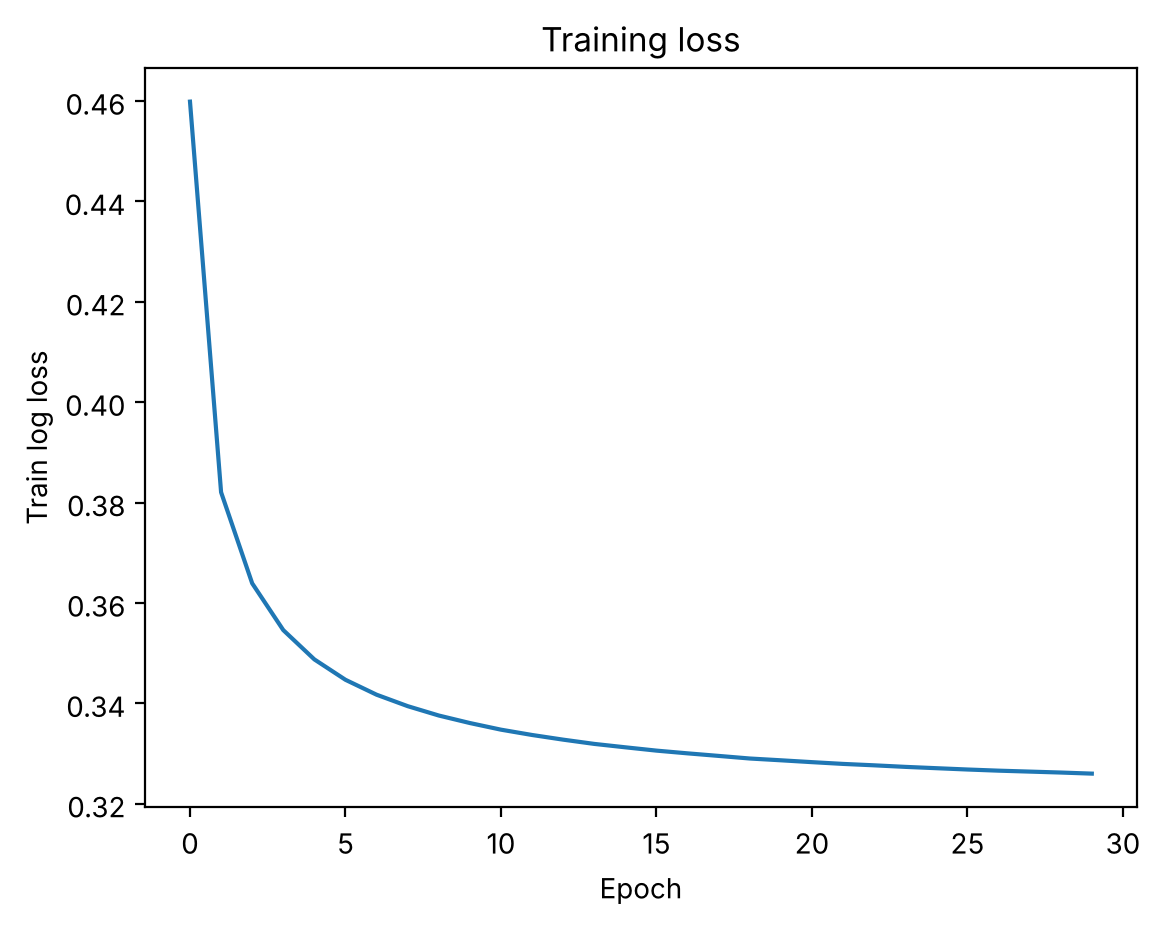

In [8]:
optimizer = optim.SGD(model.parameters(), lr=0.01)
epochs = 30
history = []
for epoch in range(epochs):
    model.train()
    running = 0.0
    for X_batch, y_batch in train_loader:
        loss = criterion(model(X_batch), y_batch)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        running += loss.item() * len(X_batch)
    history.append(running / len(X_train_tensor))

plt.plot(history); plt.xlabel('Epoch'); plt.ylabel('Train log loss'); plt.title('Training loss'); plt.show()

=== Mini-batch SGD ===
Accuracy : 0.8548
Precision: 0.7403
Recall   : 0.6110
F1       : 0.6695
ROC-AUC  : 0.9070
Log loss : 0.3182

              precision    recall  f1-score   support

       <=50K       0.88      0.93      0.91      4945
        >50K       0.74      0.61      0.67      1568

    accuracy                           0.85      6513
   macro avg       0.81      0.77      0.79      6513
weighted avg       0.85      0.85      0.85      6513



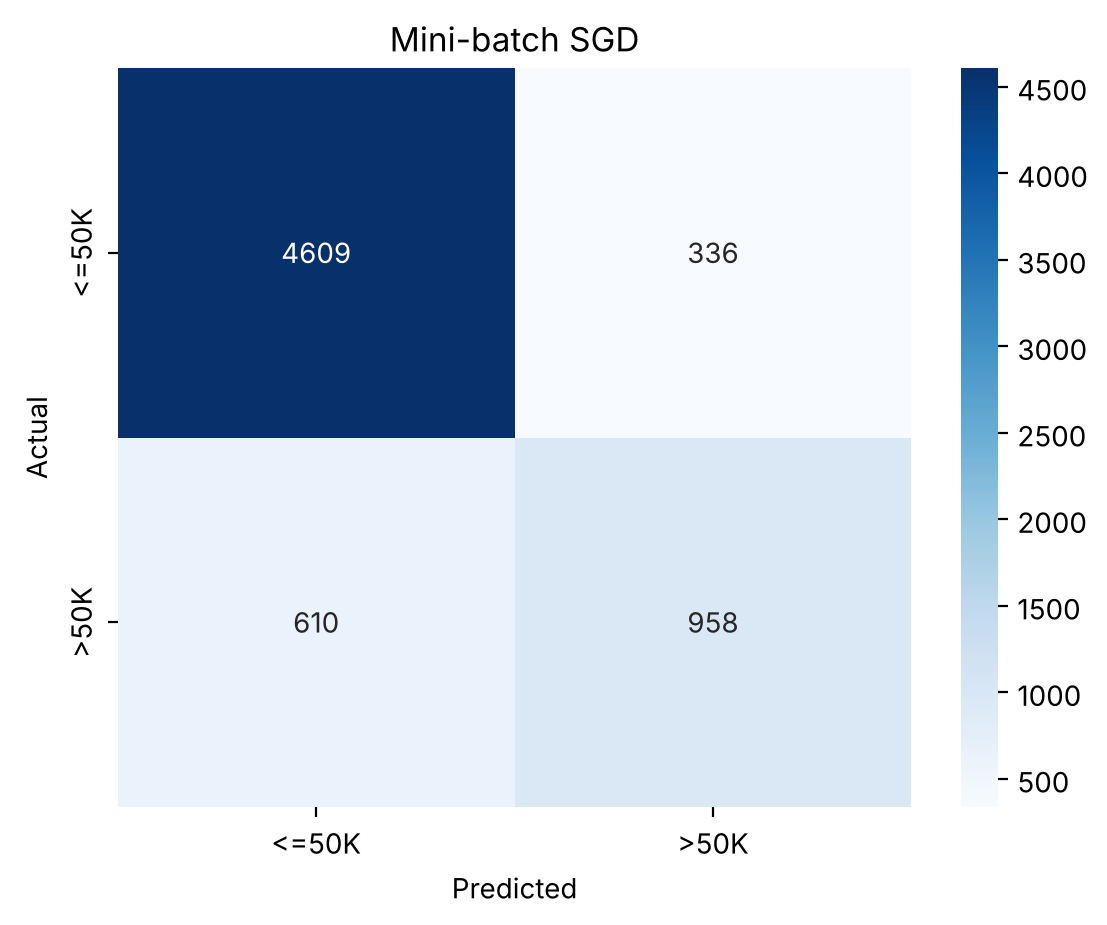

In [9]:
model.eval()
with torch.no_grad():
    y_proba = torch.sigmoid(model(X_test_tensor)).numpy().ravel()
y_pred = (y_proba >= 0.5).astype(int)
evaluate(y_test.values, y_pred, y_proba, NAME)